# Function 3 - Week 10: Exploration review

Review the round 9 return received on **25 November 2026 at 12:51 GMT**. The official snapshot contains **15 starting observations and nine returns (24 rows)** across 3 input coordinates.

The latest signed output is **-0.008109357492**, ranked **2/24**. Four queries remain per function, including Week 10.

Continue in [model predictions](model_predictions.ipynb) and the [week-level report](../report.md).

In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review, remaining_exploration_queries
from plot_helpers import (
    PLOT_CONFIG, plot_output_number_line, plot_sampling_gap_projections,
    plot_fixed_exploration_projections,
)
from three_input_model_helpers import plot_observed_input_cloud
print("Python:", sys.executable)


Python: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
# Settings for this run. Preserve the saved planning coordinates at full precision.
FUNCTION_NUMBER = 3
CURRENT_WEEK = 10
INPUT_COLUMNS = ["x1", "x2", "x3"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 15, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1}
ANALYSIS_DIR = Path.cwd().resolve()
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK}"
FIRST_PLAN_WEEK = 2
PORTAL_DECIMALS = 6
PLANNED_QUERIES = pd.DataFrame([
    [0.9545240919577334, 0.8194703192896731, 0.04216282607444466],
    [0.3523200058361702, 0.9307991516470914, 0.8498485887799658],
    [0.9038419399841349, 0.2689031599827457, 0.8751995976599097],
], columns=INPUT_COLUMNS)
OUTPUT_ZOOM_LIMITS = (-0.15, 0.0)
INPUT_PAIRS = [("x1", "x2"), ("x1", "x3"), ("x2", "x3")]
STORYBOARD_SIZE = (14, 9.4)
CLOUD_SETTINGS = dict(colourscale="Plasma", width=850, height=560)
WEEK_DIR = ANALYSIS_DIR.parent


In [3]:
# Validate the snapshot before plotting it.
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))
print(review["report"])


,observation_id,source_round,x1,x2,x3,y,output_rank
23,round-09,9,0.52,0.58,0.45,-0.008109,2


Latest recorded submission: round 9 (1 new output).
Compared with 23 earlier observations (24 outputs in total).
Earlier output range: [-0.398925513146, -0.00495200082184].

round-09: y = -0.008109357492 (negative); rank 2/24 (1 = highest output).
Inputs: x1 = 0.52, x2 = 0.58, x3 = 0.45
Within the earlier output range.


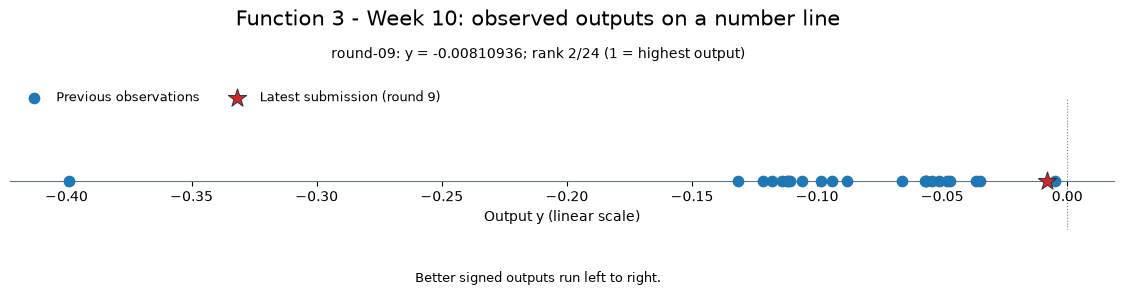

In [4]:
# Original output units and ranks, followed by a display-only zoom.
plot_output_number_line(
    review, title=f"{TITLE}: observed outputs on a number line",
    save_to=FIGURES_DIR / "output-number-line.png",
)

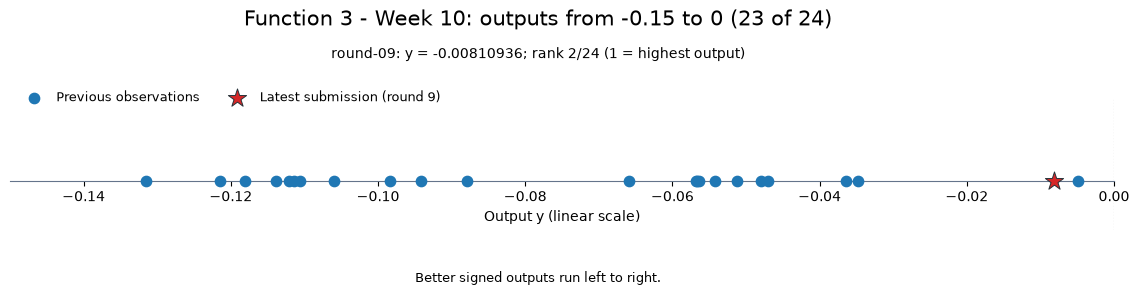

In [5]:
outputs_in_zoom = int(review["outputs"].between(*OUTPUT_ZOOM_LIMITS).sum())
plot_output_number_line(
    review, output_limits=OUTPUT_ZOOM_LIMITS,
    title=f"{TITLE}: outputs from {OUTPUT_ZOOM_LIMITS[0]:g} to {OUTPUT_ZOOM_LIMITS[1]:g} ({outputs_in_zoom} of {len(review['data'])})",
    save_to=FIGURES_DIR / "output-number-line-zoom.png",
)

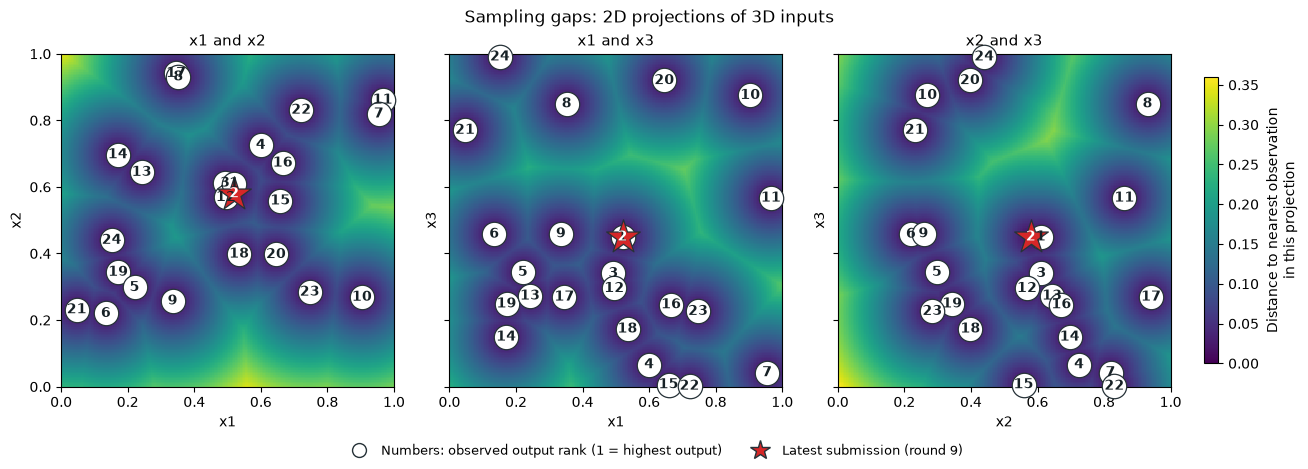

In [6]:
# These distances are measured within each displayed input-pair projection.
plot_sampling_gap_projections(
    review["plot_data"], input_columns=INPUT_COLUMNS, pairs=INPUT_PAIRS,
    highlight=review["latest_mask"], highlight_label=f"Latest submission (round {review['latest_round']})",
    save_to=FIGURES_DIR / "sampling-gaps.png",
)

In [7]:
# All three axes are inputs; measured output is colour, with no fitted surface.
cloud = plot_observed_input_cloud(
    review["inputs"].to_numpy(), review["outputs"].to_numpy(),
    title=f"Function {FUNCTION_NUMBER}: observed outputs in the three-input space", **CLOUD_SETTINGS,
    save_to=FIGURES_DIR / "observed-input-cloud.html",
)
cloud.show(config={**PLOT_CONFIG, "responsive": CLOUD_SETTINGS["width"] is None})

In [8]:
# Filter this display only; calculations and observed ranks retain every observation.
cloud_zoom = plot_observed_input_cloud(
    review["inputs"].to_numpy(), review["outputs"].to_numpy(), output_limits=OUTPUT_ZOOM_LIMITS,
    title=f"Function {FUNCTION_NUMBER}: outputs from {OUTPUT_ZOOM_LIMITS[0]:g} to {OUTPUT_ZOOM_LIMITS[1]:g} ({outputs_in_zoom} of {len(review['data'])})",
    best_label="Best output in this view", **CLOUD_SETTINGS,
    save_to=FIGURES_DIR / "observed-input-cloud-zoom.html",
)
cloud_zoom.show(config={**PLOT_CONFIG, "responsive": CLOUD_SETTINGS["width"] is None})

The following storyboard records the completed Week 2–4 fixed plan only. The model-led points through round 9 appear in the current coverage view above.

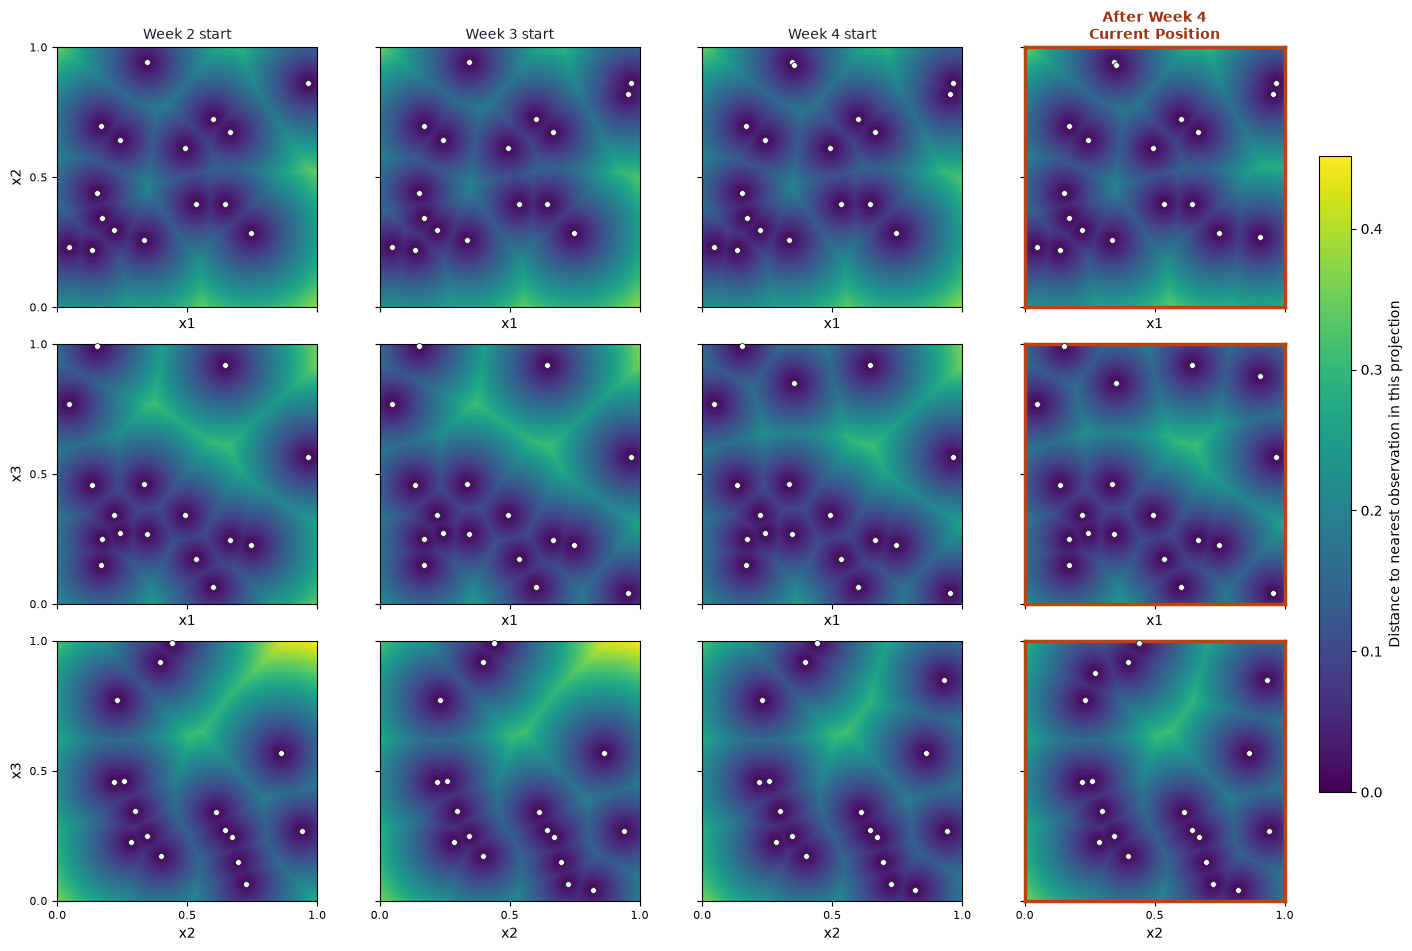

In [9]:
# Recorded official inputs establish the timeline, including their portal precision.
plot_fixed_exploration_projections(
    review["data"].loc[review["data"].source_round < 5], PLANNED_QUERIES, current_week=5,
    first_plan_week=FIRST_PLAN_WEEK, pairs=INPUT_PAIRS, figsize=STORYBOARD_SIZE,
    save_to=FIGURES_DIR / "fixed-exploration-progression-projections.png",
)

In [10]:
# An empty table means the predetermined shortlist has no remaining query.
remaining_plan = remaining_exploration_queries(
    PLANNED_QUERIES, current_week=CURRENT_WEEK, first_plan_week=FIRST_PLAN_WEEK, precision=PORTAL_DECIMALS,
)
display(remaining_plan.style.format({column: f"{{:.{PORTAL_DECIMALS}f}}" for column in INPUT_COLUMNS}))

,x1,x2,x3,Portal input
Week,,,,


In [11]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's own week folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from exploration_review_helpers import load_exploration_review
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_input_profiles,
    plot_output_review, plot_round_progress,
)
from query_budget import remaining_queries

prepared = prepare_weekly_observation_review(review)

from observation_review_helpers import replay_weekly_forecast

### Progress across completed rounds

The initial rows form one starting batch. Compare each return with the best known before that round.

In [12]:
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]]
    .rename(columns={"returned_y": "Returned output", "best_y": "Best observed after stage",
                     "change_vs_prior_best": "Return minus previous best"})
    .style.format(precision=6, na_rep="Not applicable"))


,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,Not applicable,-0.034835,Not applicable
Round 1,-0.056431,-0.034835,-0.021596
Round 2,-0.051282,-0.034835,-0.016447
Round 3,-0.054209,-0.034835,-0.019373
Round 4,-0.056642,-0.034835,-0.021807
Round 5,-0.098369,-0.034835,-0.063534
Round 6,-0.121417,-0.034835,-0.086581
Round 7,-0.065874,-0.034835,-0.031039
Round 8,-0.004952,-0.004952,0.029883


### Replay the archived Week 9 fits at the submitted input

The exported weekly fits predate round 9. Evaluate them at the exact submitted coordinates. Some final choices used different decision models and broader peer evidence. GP latent SD describes modelled uncertainty about the latent score. Neural seed SD describes variation between the three training seeds.

In [13]:
# Replay the frozen Week 9 weekly fits at the actual submitted coordinates.
stage_dir = shared_dir.parent.parent
feedback = json.loads((stage_dir / "submissions/round-09-results.json").read_text(encoding="utf-8"))
submission_path = stage_dir / feedback["proposals_source"]
if (feedback["round"] != CURRENT_WEEK - 1
        or hashlib.sha256(submission_path.read_bytes()).hexdigest() != feedback["proposals_sha256"]):
    raise ValueError("Archived submission does not match the round result.")
actual_point = prepared["latest"][INPUT_COLUMNS].to_numpy(dtype=float)
actual_output = float(prepared["latest"][OUTPUT_COLUMN])
result = feedback["results"][FUNCTION_NUMBER - 1]
portal_input = "-".join(f"{value:.6f}" for value in actual_point)
if (result["function"] != FUNCTION_NUMBER or not result["matches_proposal"]
        or result["point"] != actual_point.tolist() or result["output"] != actual_output
        or result["observations"] != len(review["data"])
        or portal_input != result["portal_input"]
        or portal_input != submission_path.read_text(encoding="utf-8").splitlines()[FUNCTION_NUMBER - 1]):
    raise ValueError("Official observation does not match the submitted and returned evaluation.")
previous_week = WEEK_DIR.parent / f"Week_{CURRENT_WEEK - 1:02d}"
previous_analysis = previous_week / "official" if ANALYSIS_DIR.name == "official" else previous_week
historical_forecast = replay_weekly_forecast(previous_analysis, function=FUNCTION_NUMBER,
    week=CURRENT_WEEK - 1, input_columns=INPUT_COLUMNS, point=actual_point)
scale = historical_forecast["height_scale"]
actual_target = float(signed_log(actual_output, scale=scale)) if scale is not None else actual_output
historical_forecast.update(
    source=(previous_analysis / "figures/neural-network-explorer.html").relative_to(stage_dir).as_posix(),
    portal_input=portal_input, actual_output=actual_output, actual_in_prediction_units=actual_target,
    actual_minus_gp_mean=actual_target - historical_forecast["gp_mean"],
    actual_minus_neural_mean=actual_target - historical_forecast["neural_mean"],
)
display(pd.Series(historical_forecast).drop(["official_snapshot_sha256", "explorer_sha256"]))


gp_model                                                       Gaussian process
data_scope                                         official_plus_retained_peers
prediction_units                                                       output y
height_scale                                                               None
gp_mean                                                               -0.014328
gp_latent_sd                                                           0.017962
neural_architecture                                                     tanh-16
neural_mean                                                           -0.016313
neural_seed_sd                                                         0.000179
source                        notebooks/Function_3/Week_09/official/figures/...
portal_input                                         0.520000-0.580000-0.450000
actual_output                                                         -0.008109
actual_in_prediction_units              

### What the return adds

With x1 and x3 fixed, the x2 midpoint scored −0.00810936, below the official x2 = 0.610000 return and the peer score at x2 = 0.550000. The local response can vary substantially over a small x2 change.

In [14]:
# Full-precision review record; tiny signed outputs are never rounded to zero.
observation_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(review["data"]),
    "latest_id": prepared["latest"]["observation_id"],
    "latest_output": float(prepared["latest"][OUTPUT_COLUMN]),
    "latest_rank": int(review["latest_submissions"].iloc[0]["output_rank"]),
    "rank_definition": "1 = highest output",
    "best_id": prepared["incumbent"]["observation_id"],
    "best_observed_output": float(prepared["incumbent"][OUTPUT_COLUMN]),
    "positive_outputs": int((review["outputs"] > 0).sum()),
    "negative_outputs": int((review["outputs"] < 0).sum()),
    "exact_zeros": int((review["outputs"] == 0).sum()),
    "progress": prepared["progress"].fillna("not_applicable").to_dict(orient="records"),
    "official_history_comparison": prepared["neighbour_summary"],
    "historical_forecast": historical_forecast,
    "remaining_queries": remaining_queries(WEEK_DIR),
}
(ANALYSIS_DIR / "observation-review.json").write_text(
    json.dumps(observation_summary, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print(json.dumps(observation_summary, indent=2))


{
  "function": 3,
  "week": 10,
  "observations": 24,
  "latest_id": "round-09",
  "latest_output": -0.00810935749199673,
  "latest_rank": 2,
  "rank_definition": "1 = highest output",
  "best_id": "round-08",
  "best_observed_output": -0.004952000821836788,
  "positive_outputs": 0,
  "negative_outputs": 24,
  "exact_zeros": 0,
  "progress": [
    {
      "source_round": 0,
      "stage": "Initial batch",
      "returned_y": "not_applicable",
      "best_y": -0.034835313350078584,
      "change_vs_prior_best": "not_applicable"
    },
    {
      "source_round": 1,
      "stage": "Round 1",
      "returned_y": -0.0564311593911001,
      "best_y": -0.034835313350078584,
      "change_vs_prior_best": -0.021595846041021514
    },
    {
      "source_round": 2,
      "stage": "Round 2",
      "returned_y": -0.051282396335886896,
      "best_y": -0.034835313350078584,
      "change_vs_prior_best": -0.016447082985808312
    },
    {
      "source_round": 3,
      "stage": "Round 3",
      "r

### Course lifecycle for this review

1. **Define the goal and scope** — review round 9 for the project owner and prepare descriptive evidence for the Week 10 decision.
2. **Gather the data** — use the 25 November result, the independent official snapshot and the archived Week 9 weekly fits.
3. **Explore the data** — inspect measured ranks, progress and sampling coverage or full input profiles.
4. **Clean and preprocess the data** — validate finite values, dimensions, bounds and round counts at full precision.
5. **Select and engineer features** — keep the ordered input coordinates. Additional features are unnecessary for the measured views.
6. **Define the machine-learning task** — this review describes observations for a continuous black-box maximisation task.
7. **Partition the data** — not applicable to this descriptive review. The comparison uses fits already frozen before round 9.
8. **Select and train candidate methods** — not applicable to this review. The model notebook fits and compares the candidates.
9. **Evaluate and interpret the results** — compare the latest measured value with the incumbent, earlier outputs and the archived fits at the submitted coordinates.
10. **Deploy and iterate** — deployment is not applicable to this review. Carry the evidence into the next query decision.
